Initially available jobs:
  A
  X


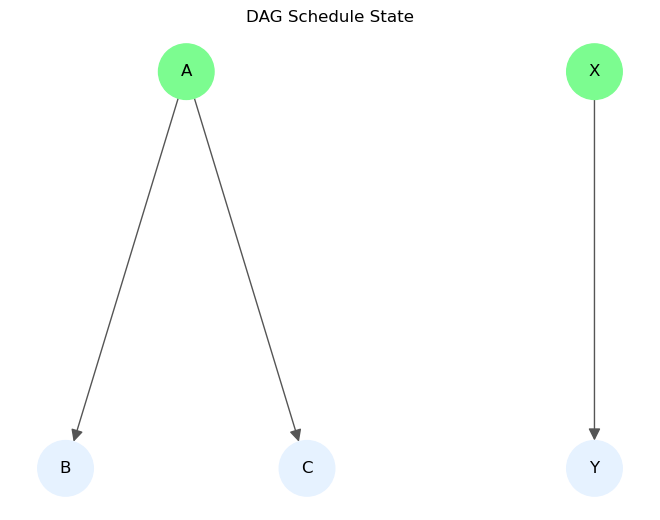


After consuming A:
  B
  C
  X


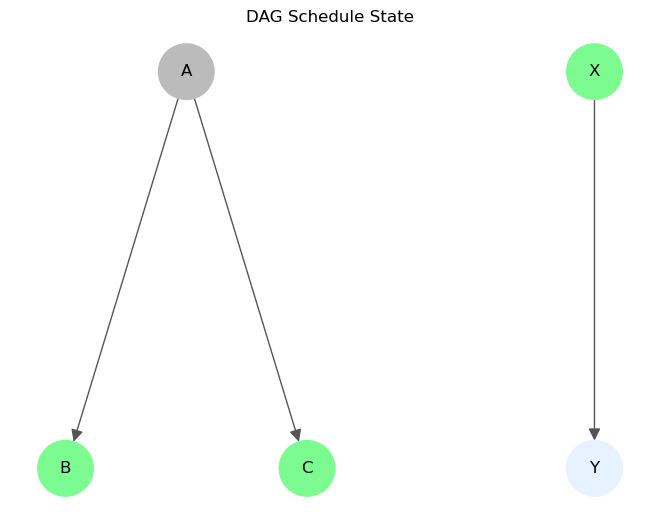


After consuming X and B:
  C
  Y


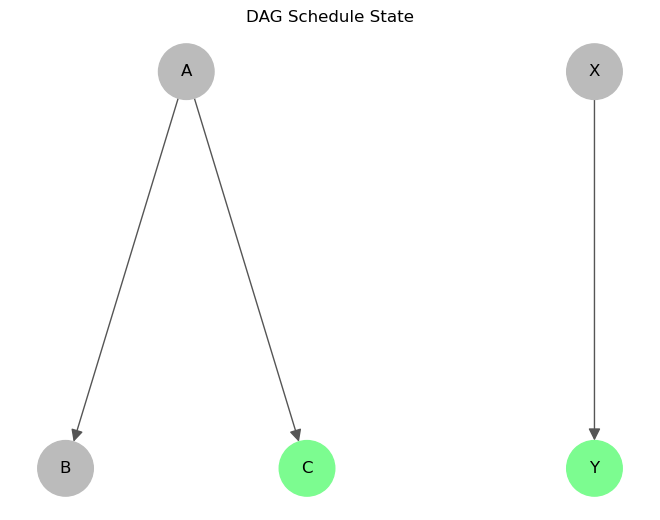

In [1]:
from job import Job
from dag import DAG
from dag_schedule import DAGSchedule


# ---------------- Define DAG jobs ----------------

A = Job("A", 0.1)
B = Job("B", 0.5)
C = Job("C", 0.8)

X = Job("X", 0.2)
Y = Job("Y", 0.9)

dag1 = DAG()
dag1.add_edge(A, B)
dag1.add_edge(A, C)

dag2 = DAG()
dag2.add_edge(X, Y)


# ---------------- Initialize schedule ----------------

sched = DAGSchedule([dag1, dag2])


# ---------------- Step 0: initial state ----------------

print("Initially available jobs:")
for dag, job in sched.available():
    print(f"  {job.name}")

sched.draw()


# ---------------- Step 1: consume A ----------------

sched.consume(dag1, A)

print("\nAfter consuming A:")
for dag, job in sched.available():
    print(f"  {job.name}")

sched.draw()


# ---------------- Step 2: consume X and B ----------------

sched.consume(dag2, X)
sched.consume(dag1, B)

print("\nAfter consuming X and B:")
for dag, job in sched.available():
    print(f"  {job.name}")

sched.draw()